# Fig 2: Power across the computing stack (paper version)

Full-width figure with two panels, drawn at print size (7.0 in wide):
- **(a) Processor power** from `Data/generated/processors_clean.csv`. **Run `fig2a_processor_power.ipynb` first**; it builds that file.
- **(b) Rack power** from `Data/generated/racks.csv`, AI and HPC systems only.

Titles and sources go in the LaTeX caption, not in the figure. Labels are short system names; the values are in the CSVs.
Systems left off panel (b) on purpose are listed in `EXCLUDE_RACKS` below.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
from pathlib import Path
import paper_style as ps

ps.apply()
DATA = Path('../Data')
OUT = Path('../figures'); OUT.mkdir(exist_ok=True)

## Data

In [3]:
procs = pd.read_csv(DATA / 'generated/processors_clean.csv', parse_dates=['date'])

racks = pd.read_csv(DATA / 'generated/racks.csv', dtype=str)
racks['kW'] = pd.to_numeric(racks['rack_kW'].str.lstrip('~'), errors='coerce')
racks['year'] = racks['year'].astype(int)

# Left off panel (b): low-confidence values, and Catalina (a GB200 NVL72 variant, duplicates that point)
EXCLUDE_RACKS = ['AMD Helios (MI400 series)', 'Huawei CloudMatrix 384', 'NVIDIA DGX-2 (V100)', 'Meta Catalina (GB200)']
rack_pts = racks[racks['category'].isin(['ai_accelerator', 'hpc']) & racks['kW'].notna()
                 & ~racks['system'].isin(EXCLUDE_RACKS)].copy()
rack_pts[['system', 'year', 'kW', 'category', 'status', 'confidence']].sort_values('year')

,system,year,kW,category,status,confidence
12,IBM BlueGene/L (LLNL),2005,22.0,hpc,shipped,high
13,Cray XT5 Jaguar (ORNL),2009,35.0,hpc,shipped,high
14,IBM BlueGene/Q Sequoia (LLNL),2012,82.0,hpc,shipped,high
15,Cray XK7 Titan (ORNL),2012,41.0,hpc,shipped,high
27,NVIDIA DGX-1 (P100),2016,29.0,ai_accelerator,shipped,medium
17,IBM Summit AC922 (ORNL),2018,39.0,hpc,shipped,high
18,Fujitsu Fugaku (RIKEN),2020,69.0,hpc,shipped,high
29,NVIDIA DGX A100 SuperPOD,2020,26.0,ai_accelerator,shipped,high
19,HPE Cray EX Frontier (ORNL),2022,285.0,hpc,shipped,high
30,NVIDIA DGX H100 SuperPOD,2023,41.0,ai_accelerator,shipped,high


## Labels
Offsets are in points (dx, dy) from the marker, with horizontal alignment. Tuned by eye after rendering.

In [4]:
# (a): text sits in a column in the empty upper-left, with leader lines; ordered by target power so lines don't cross
PROC_LABELS = {  # product -> (label, text x, text y)
    'NVIDIA GB300 (Blackwell Ultra)': ('AMD MI355X, NVIDIA GB300', '2007-01-01', 1250),
    'Google TPU v7 Ironwood': ('Google TPU v7', '2007-01-01', 1130),
    'Intel Habana Gaudi3': ('Intel Gaudi 3', '2007-01-01', 1010),
    'AMD Instinct MI300X': ('AMD MI300X', '2007-01-01', 890),
    'NVIDIA H100 SXM5 80GB': ('NVIDIA H100', '2007-01-01', 770),
    'Intel Xeon 6980P': ('Intel Xeon 6980P (CPU)', '2007-01-01', 650),
    'Google TPU v3': ('Google TPU v3', '2007-01-01', 530),
    'NVIDIA Tesla K80': ('NVIDIA K80', '2007-01-01', 410),
}
RACK_LABELS = {  # system -> (label, dx, dy, ha)
    'IBM BlueGene/L (LLNL)': ('BlueGene/L', 4, 0, 'left'),
    'Cray XT5 Jaguar (ORNL)': ('Jaguar', 4, 0, 'left'),
    'IBM BlueGene/Q Sequoia (LLNL)': ('Sequoia', -4, 0, 'right'),
    'Cray XK7 Titan (ORNL)': ('Titan', 4, 0, 'left'),
    'IBM Summit AC922 (ORNL)': ('Summit', 4, -1, 'left'),
    'Fujitsu Fugaku (RIKEN)': ('Fugaku', -4, 0, 'right'),
    'HPE Cray EX Frontier (ORNL)': ('Frontier', -4, 0, 'right'),
    'HPE Cray EX Aurora (ANL)': ('Aurora', -4, 0, 'right'),
    'HPE Cray EX El Capitan (LLNL)': ('El Capitan', -4, 0, 'right'),
    'NVIDIA DGX-1 (P100)': ('DGX-1', -4, 0, 'right'),
    'NVIDIA DGX A100 SuperPOD': ('DGX A100', 0, -7, 'center'),
    'NVIDIA DGX H100 SuperPOD': ('DGX H100', 4, 0, 'left'),
    'NVIDIA DGX B200': ('DGX B200', 4, 0, 'left'),
    'NVIDIA GB200 NVL72': ('GB200 NVL72', -4, 0, 'right'),
    'NVIDIA GB300 NVL72': ('GB300 NVL72', 4, 0, 'left'),
    'AMD Instinct MI355X platform': ('AMD MI355X', 4, -2, 'left'),
    'NVIDIA Vera Rubin NVL72': ('Vera Rubin NVL72', 4, 0, 'left'),
    'NVIDIA Rubin Ultra NVL576 (Kyber)': ('Kyber NVL576', -5, 0, 'right'),
    'Google TPU v7 Ironwood superpod': ('Google TPU v7', 4, 0, 'left'),
    'Tesla Dojo ExaPOD cabinet': ('Tesla Dojo', -4, 0, 'right'),
}

def label(ax, x, y, spec):
    text, dx, dy, ha = spec
    ax.annotate(text, xy=(x, y), xytext=(dx, dy), textcoords='offset points', ha=ha, va='center',
                fontsize=6, color=ps.TEXT)

## Figure

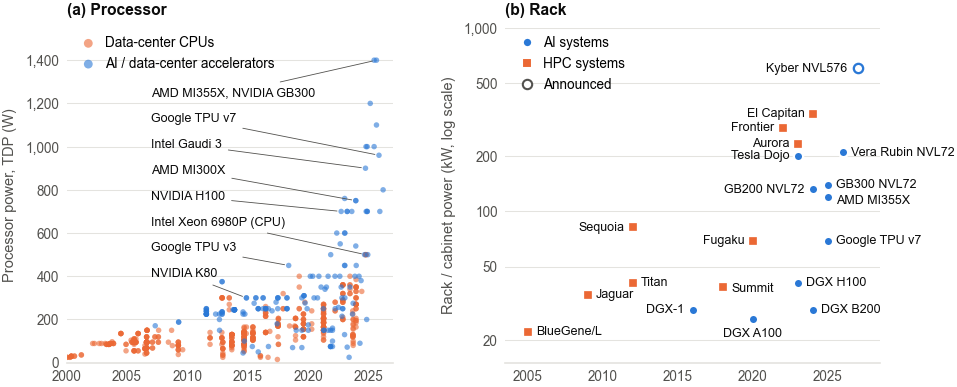

In [5]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(ps.TEXT_W, 2.9), gridspec_kw={'width_ratios': [1, 1.15], 'wspace': 0.32})

# (a) Processor power
for group, color, name in [('Data-center CPU', ps.C_GP, 'Data-center CPUs'),
                           ('AI / data-center accelerator', ps.C_AI, 'AI / data-center accelerators')]:
    d = procs[procs['group'] == group]
    ax_a.scatter(d['date'], d['tdp_W'], s=7, color=color, alpha=0.6, edgecolor='none', label=name, zorder=3)
for product, (text, tx, ty) in PROC_LABELS.items():
    row = procs[procs['product'] == product]
    if len(row):
        ax_a.annotate(text, xy=(row['date'].iloc[0], row['tdp_W'].iloc[0]), xytext=(pd.Timestamp(tx), ty),
                      fontsize=6, color=ps.TEXT, va='center', ha='left',
                      arrowprops=dict(arrowstyle='-', color=ps.TEXT_2, lw=0.4, shrinkA=1, shrinkB=2))
ax_a.set_xlim(pd.Timestamp('2000-01-01'), pd.Timestamp('2027-01-01'))
ax_a.xaxis.set_major_locator(mdates.YearLocator(5, month=1, day=1))
ax_a.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax_a.set_ylim(0, 1550)
ax_a.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax_a.set_ylabel('Processor power, TDP (W)')
ax_a.legend(loc='upper left', frameon=False, handletextpad=0.2, borderaxespad=0.2, markerscale=1.6)
ps.panel_label(ax_a, '(a) Processor')

# (b) Rack power
GROUP = {'ai_accelerator': ('AI systems', ps.C_AI, 'o'), 'hpc': ('HPC systems', ps.C_GP, 's')}
for _, r in rack_pts.iterrows():
    _, color, marker = GROUP[r['category']]
    hollow = r['status'] == 'announced'
    ax_b.scatter(r['year'], r['kW'], s=20, marker=marker, linewidth=1.1, zorder=4,
                 facecolor='white' if hollow else color, edgecolor=color if hollow else 'white')
    if r['system'] in RACK_LABELS:
        label(ax_b, r['year'], r['kW'], RACK_LABELS[r['system']])
ax_b.set_yscale('log')
ax_b.yaxis.set_major_locator(FixedLocator([20, 50, 100, 200, 500, 1000]))
ax_b.yaxis.set_minor_locator(NullLocator())
ax_b.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax_b.set_ylim(15, 1000)
ax_b.set_xlim(2003.5, 2028.5)
ax_b.set_xticks(range(2005, 2030, 5))
ax_b.set_ylabel('Rack / cabinet power (kW, log scale)')
handles = [Line2D([], [], ls='', marker=m, ms=4.5, mfc=c, mec='white', label=l) for l, c, m in GROUP.values()]
handles.append(Line2D([], [], ls='', marker='o', ms=4.5, mfc='white', mec=ps.TEXT_2, mew=1, label='Announced'))
ax_b.legend(handles=handles, loc='upper left', frameon=False, handletextpad=0.2, borderaxespad=0.2)
ps.panel_label(ax_b, '(b) Rack')

fig.savefig(OUT / 'fig2_power_trends.pdf')
fig.savefig(OUT / 'fig2_power_trends.png', dpi=300)
plt.show()